# Preset and definition of variables
Importação de bibliotecas base, configuração do ambiente visual e definição de variáveis globais e caminhos para a validação *single-subject*.

In [1]:
import os
import zipfile
import mne
import mne_nirs
import mne_nirs.io
from mne_nirs.channels import get_long_channels, get_short_channels, picks_pair_to_idx
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from nilearn.glm.first_level import make_first_level_design_matrix

# Definição de Variáveis Globais (Single-Subject) com Caminho Absoluto
BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
RUN = "sub-001_ses-01_tk-dm_run-1_nirs_001"
SNIRF_FILE = "2026-08-04_002.snirf"
ZIP_FILE = "2026-08-04_002.zip"

pasta_alvo = os.path.join(BASE_DIR, SUJEITO, "nirs", RUN)
caminho_snirf = os.path.join(pasta_alvo, SNIRF_FILE)
caminho_zip = os.path.join(pasta_alvo, ZIP_FILE)
pasta_extraida_wings = os.path.join(pasta_alvo, "dados_wings_extraidos")

# 1. Carregamento de Dados e Inspeção Inicial (Raw Signal)
Extração dos dados periféricos WINGS (SPA-fNIRS), leitura do ficheiro `.snirf` e renderização estática (`Agg`) da montagem da touca e da densidade ótica bruta para garantir a estabilidade do Kernel.

A ler o ficheiro fNIRS:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\2026-08-04_002.snirf

Duração da Gravação: 424.87 segundos
Frequência de Amostragem (Hz): 10.17
Triggers encontrados: ['100', '110', '120', '130', '150', '160']

A desenhar topologia da touca 2D...
Using matplotlib as 2D backend.


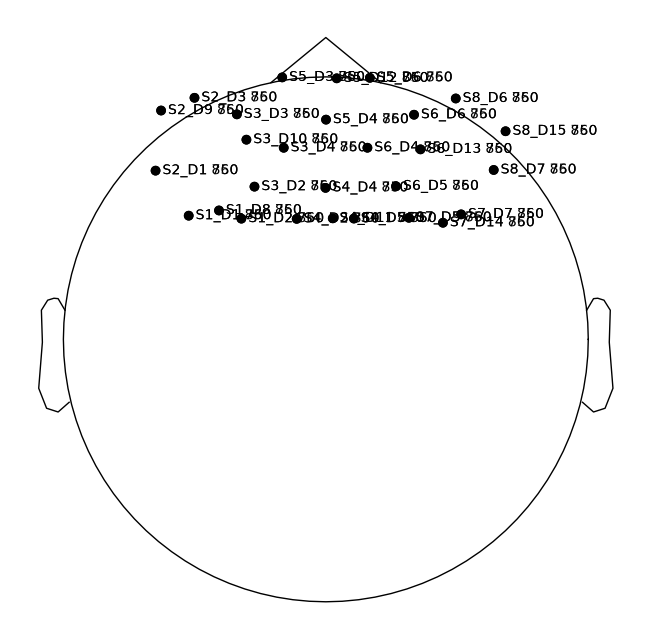

A processar Densidade Ótica (OD)...


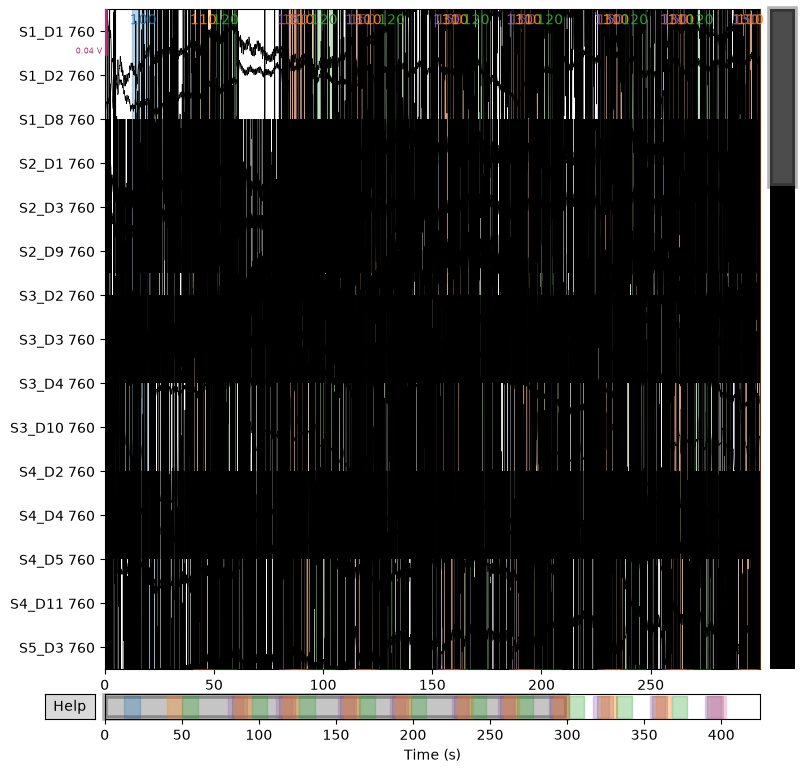


Processamento visual concluído com sucesso!


In [2]:
import os
import zipfile
import mne
import mne_nirs
import matplotlib.pyplot as plt

# 1.1 Extrair dados WINGS se necessário
if os.path.exists(caminho_zip) and not os.path.exists(pasta_extraida_wings):
    print("A extrair dados do WINGS (SPA-fNIRS)...")
    with zipfile.ZipFile(caminho_zip, 'r') as zip_ref:
        zip_ref.extractall(pasta_extraida_wings)
    print("Extração do WINGS concluída!")

# 1.2 Carregar o sinal fNIRS bruto
print(f"A ler o ficheiro fNIRS:\n{caminho_snirf}")
raw = mne.io.read_raw_snirf(caminho_snirf, preload=True, verbose=False)

# 1.3 Inspecionar a estrutura do ficheiro
print("\n" + "="*50)
print(f"Duração da Gravação: {raw.times[-1]:.2f} segundos")
print(f"Frequência de Amostragem (Hz): {raw.info['sfreq']:.2f}")
triggers = sorted(set([str(t) for t in raw.annotations.description]))
print(f"Triggers encontrados: {triggers}")
print("="*50)

# 1.4 Visualizar a Montagem da Touca (Optódes) em 2D
print("\nA desenhar topologia da touca 2D...")
mne.viz.set_browser_backend('matplotlib') 
fig_montagem_2d = raw.plot_sensors(show_names=True)
plt.show() # Usa plt.show() em vez de fig.show()

# 1.5 Converter para Densidade Ótica (OD) e mostrar o sinal
print("A processar Densidade Ótica (OD)...")
raw_od = mne.preprocessing.nirs.optical_density(raw)

# Desenhar a OD (apenas os primeiros 15 canais)
fig_od = raw_od.plot(
    n_channels=15, 
    duration=300
)
plt.show() # Usa plt.show() em vez de fig.show()

print("\nProcessamento visual concluído com sucesso!")

# 1.6 Controlo de Qualidade do Sinal: Scalp Coupling Index (SCI)
Cálculo do índice de acoplamento (SCI) para avaliar o contacto ótimo entre optódes e escalpe. Exclusão automática de canais com sinal de baixa qualidade (SCI < 0.7).

A calcular o Scalp Coupling Index (SCI)...


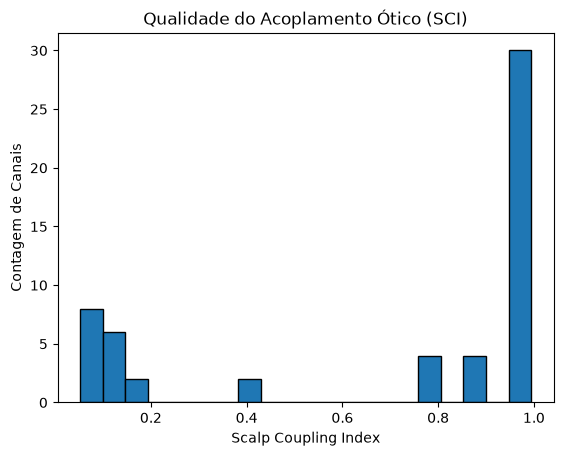


Canais marcados como maus (SCI < 0.7): 18
['S1_D8 760', 'S2_D9 760', 'S3_D2 760', 'S3_D10 760', 'S4_D11 760', 'S5_D12 760', 'S6_D13 760', 'S7_D14 760', 'S8_D15 760', 'S1_D8 850', 'S2_D9 850', 'S3_D2 850', 'S3_D10 850', 'S4_D11 850', 'S5_D12 850', 'S6_D13 850', 'S7_D14 850', 'S8_D15 850']


In [3]:
# Calcular o Scalp Coupling Index (SCI)
print("A calcular o Scalp Coupling Index (SCI)...")
sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)

# Desenhar Histograma do SCI
fig_sci, ax = plt.subplots()
ax.hist(sci, bins=20, edgecolor='black')
ax.set(xlabel='Scalp Coupling Index', ylabel='Contagem de Canais', title='Qualidade do Acoplamento Ótico (SCI)')
plt.show()

# Marcar os canais com SCI < 0.7 como "Bads" para que as funções seguintes os ignorem
LIMIAR_SCI = 0.7
bads_sci = list(np.array(raw_od.ch_names)[sci < LIMIAR_SCI])
raw_od.info['bads'] = bads_sci

print(f"\nCanais marcados como maus (SCI < {LIMIAR_SCI}): {len(bads_sci)}")
if len(bads_sci) > 0:
    print(bads_sci)

# 2. Limpeza do Sinal: Correção de Movimento (TDDR) e Ruído Sistémico (SSR)
Aplicação do algoritmo *Temporal Derivative Distribution Repair* (TDDR) para correção robusta de picos/desvios abruptos, seguida da Regressão de Canais Curtos (SSR) para atenuar o ruído da fisiologia sistémica (fluxo sanguíneo no couro cabeludo).

A aplicar TDDR (Correção de Movimento)...


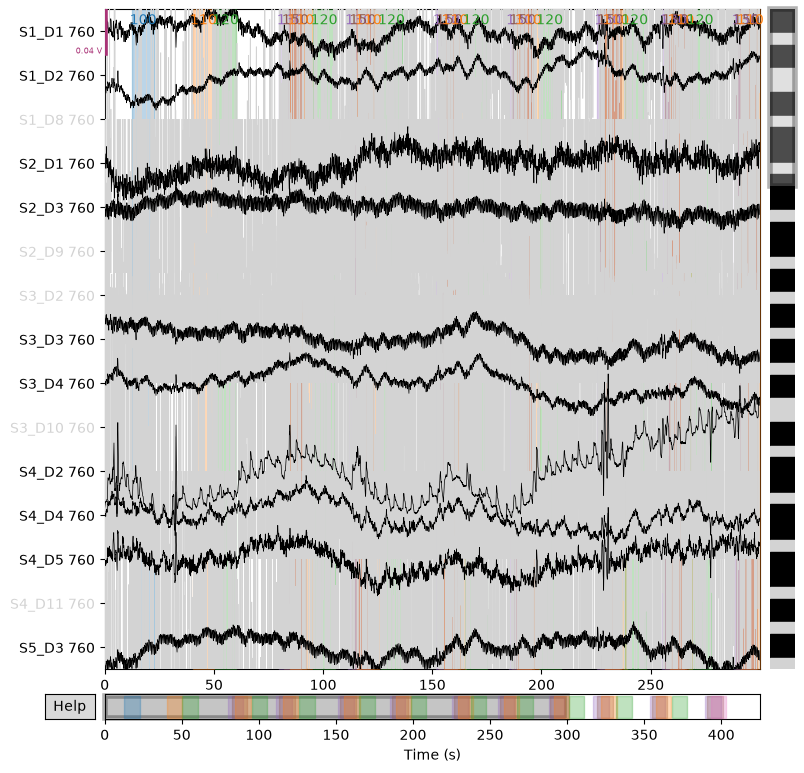


A verificar viabilidade da Regressão de Canais Curtos (SSR)...
AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.
A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtro.


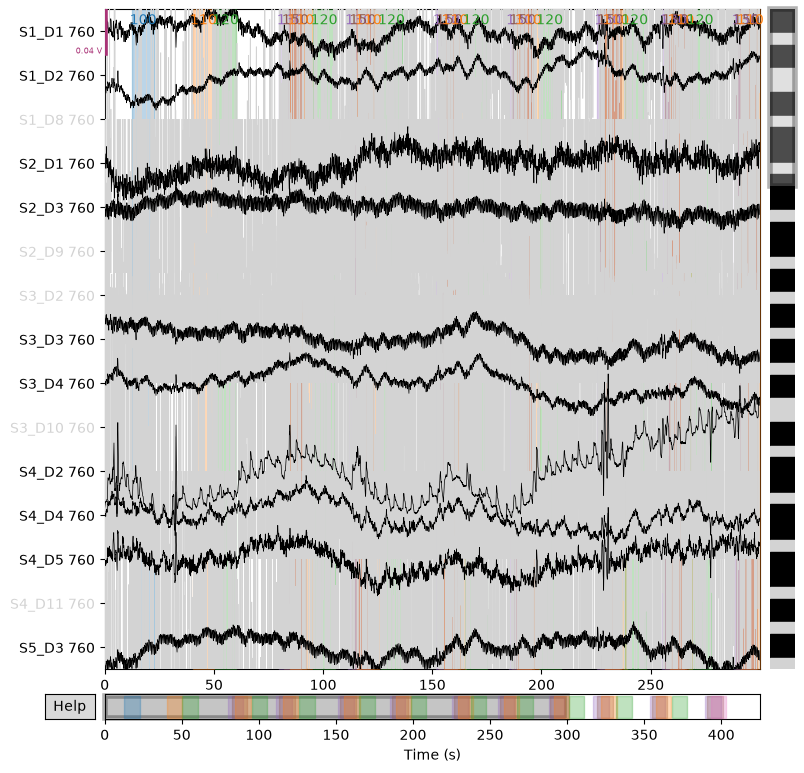


Bloco de limpeza de artefactos concluído!


In [5]:
# 2.1 Correção de Movimento (TDDR)
print("A aplicar TDDR (Correção de Movimento)...")
raw_od_tddr = mne.preprocessing.nirs.temporal_derivative_distribution_repair(raw_od)

# Desenhar o sinal após o TDDR (apenas os primeiros 15 canais)
fig_tddr = raw_od_tddr.plot(n_channels=15, duration=300)
plt.show()

# 2.2 Regressão de Canais Curtos (SSR) Dinâmica
print("\nA verificar viabilidade da Regressão de Canais Curtos (SSR)...")

# Identificar canais que sobreviveram ao SCI e medir a sua distância
picks_validos = mne.pick_types(raw_od_tddr.info, fnirs=True, exclude='bads')
distancias = mne.preprocessing.nirs.source_detector_distances(raw_od_tddr.info, picks=picks_validos)

# Contar quantos canais curtos (<= 1.0 cm ou 0.01 m) sobreviveram
num_curtos_validos = np.sum(distancias <= 0.01)

if num_curtos_validos > 0:
    print(f"Encontrados {num_curtos_validos} canais curtos válidos. A aplicar SSR...")
    raw_od_ssr = mne_nirs.signal_enhancement.short_channel_regression(raw_od_tddr)
else:
    print("AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.")
    print("A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtro.")
    raw_od_ssr = raw_od_tddr.copy() # O sinal passa para a fase seguinte sem a regressão curta

# Desenhar o sinal final desta etapa (apenas os primeiros 15 canais)
fig_ssr = raw_od_ssr.plot(n_channels=15, duration=300)
plt.show()

print("\nBloco de limpeza de artefactos concluído!")

# 3. Conversão para Hemoglobina (mBLL) e Filtragem Temporal
Transformação da Densidade Ótica em concentrações de Oxiemoglobina (HbO) e Desoxiemoglobina (HbR) usando a Lei de Beer-Lambert Modificada (ppf=0.1). Aplicação de filtro passa-banda (0.01 Hz a 0.10 Hz) para isolar as frequências de interesse hemodinâmico.

A converter para HbO e HbR (mBLL)...
A aplicar filtro passa-banda (0.01 - 0.1 Hz)...


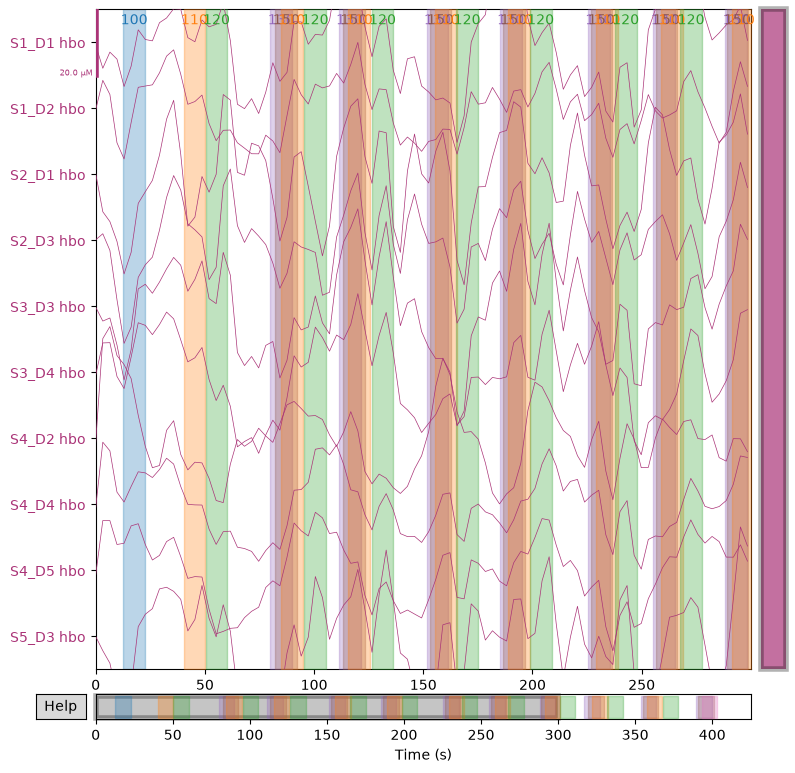


Conversão e Filtragem concluídas com sucesso!


In [6]:
# Definir parâmetros baseados no teu relatório metodológico
PPF = 0.1
LOW_CUTOFF_HZ = 0.01
HIGH_CUTOFF_HZ = 0.10

# 3.1 Lei de Beer-Lambert Modificada (mBLL)
print("A converter para HbO e HbR (mBLL)...")
raw_haemo = mne.preprocessing.nirs.beer_lambert_law(
    raw_od_ssr,
    ppf=PPF,
)

# 3.2 Filtragem Temporal (IIR)
print(f"A aplicar filtro passa-banda ({LOW_CUTOFF_HZ} - {HIGH_CUTOFF_HZ} Hz)...")
raw_filtrado = raw_haemo.filter(
    l_freq=LOW_CUTOFF_HZ,
    h_freq=HIGH_CUTOFF_HZ,
    method="iir",
    verbose=False,
)

# Desenhar o sinal final de HbO e HbR após a filtragem
# Vamos usar o pick_types para selecionar apenas alguns canais de HbO para visualização limpa
picks_hbo = mne.pick_types(raw_filtrado.info, fnirs='hbo')
fig_haemo = raw_filtrado.plot(
    picks=picks_hbo[:10], # Mostra os primeiros 10 canais de HbO
    duration=300
)
plt.show()

print("\nConversão e Filtragem concluídas com sucesso!")

# 3.3 Segmentação por Épocas (Epoching) e Visualização de ERPs
Extração de segmentos de sinal (Épocas) centrados nos marcadores de estímulo ('Video'). Alinhamento das tentativas para desenhar a curva média de resposta hemodinâmica (ERPs) com intervalo de confiança.

A construir as Épocas para o estímulo 'Video'...

Visualização das ondas Evoked (HbO) para os primeiros 4 canais cerebrais:


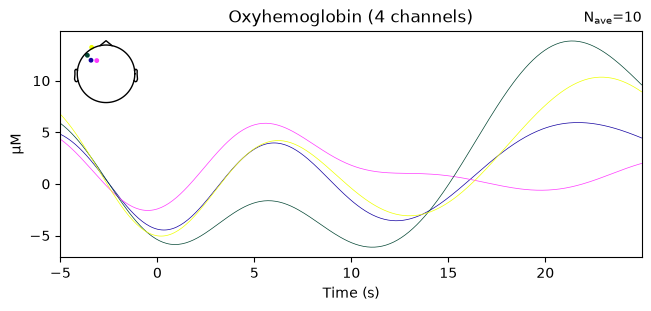


Curva Média com Intervalo de Confiança (Canal S1_D1 hbo):


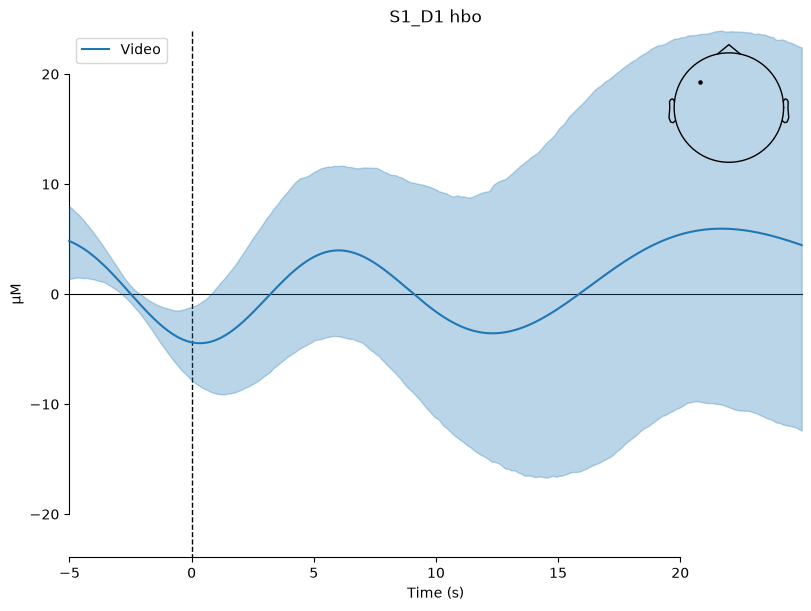

In [7]:
# 1. Renomear marcadores para o Epoching perceber (podes apagar o código igual que tinhas no bloco do GLM)
EVENTOS_DM = {
    "100": "BaselineInic", "110": "Jitter", "120": "Video", "130": "Decisao",
    "140": "RespA", "141": "RespB", "142": "RespC", "143": "RespD",
    "150": "FixPost", "160": "BaselineFin"
}
renomear = {cod: nome for cod, nome in EVENTOS_DM.items() if cod in raw_filtrado.annotations.description}
raw_filtrado.annotations.rename(renomear)

# Extrair os eventos
events, event_dict = mne.events_from_annotations(raw_filtrado, verbose=False)

# Definir janela de 5s antes do estímulo até 25s depois
tmin, tmax = -5.0, 25.0

print("A construir as Épocas para o estímulo 'Video'...")
epochs = mne.Epochs(
    raw_filtrado,
    events,
    event_id=event_dict,
    tmin=tmin,
    tmax=tmax,
    baseline=(-5.0, 0.0), # Subtrai a média da baseline (5s anteriores) à curva
    preload=True,
    verbose=False
)

if 'Video' in epochs.event_id:
    # 1. Desenhar a média (Evoked) das concentrações (ex: 4 primeiros canais de HbO)
    evoked_video = epochs['Video'].average()
    picks_hbo = mne.pick_types(evoked_video.info, fnirs='hbo', exclude='bads')
    
    print("\nVisualização das ondas Evoked (HbO) para os primeiros 4 canais cerebrais:")
    fig_evoked = evoked_video.plot(picks=picks_hbo[:4])
    plt.show()

    # 2. Desenhar o Gráfico com Intervalo de Confiança (95%) para 1 Canal Específico
    canal_alvo = raw_filtrado.ch_names[picks_hbo[0]] # Seleciona o 1º canal válido
    
    # Truque do orientador para forçar o cálculo da variância: listar tentativas individuais
    video_epochs = epochs['Video']
    evokeds_list = [video_epochs[i].average() for i in range(len(video_epochs))]
    
    print(f"\nCurva Média com Intervalo de Confiança (Canal {canal_alvo}):")
    fig_compare = mne.viz.plot_compare_evokeds(
        {'Video': evokeds_list},
        picks=[canal_alvo],
        ci=True, # Mostra a mancha do erro padrão/variância
        show_sensors='upper right'
    )
    plt.show()
else:
    print("Atenção: Marcador 'Video' não encontrado para criar épocas.")

# 4. Isolamento Cortical, Renomeação de Triggers e GLM
Exclusão de canais curtos para reter apenas os canais corticais longos. Renomeação dos marcadores do paradigma de *Decision Making* e aplicação do Modelo Linear Geral (GLM) de 1º nível.

In [8]:
# 4.1 Isolamento Cortical (manter apenas canais fNIRS longos e válidos)
print("A extrair canais corticais longos...")
picks_fnirs = mne.pick_types(raw_filtrado.info, fnirs=True, exclude="bads")

# Calcular distâncias para garantir que os canais têm pelo menos 1.5 cm
distancias = mne.preprocessing.nirs.source_detector_distances(raw_filtrado.info, picks=picks_fnirs)
DISTANCIA_MIN_LONGA_M = 0.015
picks_longos = picks_fnirs[distancias > DISTANCIA_MIN_LONGA_M]

raw_cerebral = raw_filtrado.copy().pick(picks_longos)
print(f"Canais longos corticais mantidos: {len(picks_longos)}")

# 4.2 Renomear Triggers (Decision Making)
EVENTOS_DM = {
    "100": "BaselineInic",
    "110": "Jitter",
    "120": "Video",
    "130": "Decisao",
    "140": "RespA",
    "141": "RespB",
    "142": "RespC",
    "143": "RespD",
    "150": "FixPost",
    "160": "BaselineFin",
}

print("\nA renomear marcadores...")
renomear = {
    codigo: nome
    for codigo, nome in EVENTOS_DM.items()
    if codigo in raw_cerebral.annotations.description
}
raw_cerebral.annotations.rename(renomear)
print(f"Marcadores renomeados: {set(raw_cerebral.annotations.description)}")

# 4.3 Modelo Linear Geral (GLM)
print("\nA construir a matriz de desenho e a correr o GLM...")
# IMPORTAÇÃO CORRIGIDA PARA MNE_NIRS
from mne_nirs.experimental_design import make_first_level_design_matrix 
from mne_nirs.statistics import run_glm

# Criar a matriz de desenho do 1º nível (GLM)
design_matrix = make_first_level_design_matrix(
    raw_cerebral,
    drift_model="cosine",
    high_pass=LOW_CUTOFF_HZ,
    hrf_model="glover",
)

# Executar o GLM
glm_est = run_glm(raw_cerebral, design_matrix)

# Calcular o contraste: Vídeo vs. Baseline Implícito
colunas = design_matrix.columns.tolist()
vetor_contraste = np.zeros(len(colunas))

if "Video" in colunas:
    vetor_contraste[colunas.index("Video")] = 1
    contraste = glm_est.compute_contrast(vetor_contraste)
    
    # Converter resultados num DataFrame pandas para visualizar
    df_contraste = contraste.to_dataframe()
    
    print("\nResultados do GLM (Primeiros 10 canais corticais para 'Video'):")
    display(df_contraste.head(10))
else:
    print("\nAtenção: O marcador 'Video' não foi encontrado na matriz de desenho.")

A extrair canais corticais longos...
Canais longos corticais mantidos: 38

A renomear marcadores...
Marcadores renomeados: {'Jitter', 'BaselineInic', 'Decisao', 'FixPost', 'BaselineFin', 'Video'}

A construir a matriz de desenho e a correr o GLM...

Resultados do GLM (Primeiros 10 canais corticais para 'Video'):


variable,ContrastType,effect,p_value,stat,z_score,Source,Detector,Chroma,Significant,ch_name
0,t,0.000018,3.300978e-35,12.435713,12.325516,1,1,hbo,True,S1_D1 hbo
2,t,0.000014,1.299432e-55,15.892338,15.665619,1,2,hbo,True,S1_D2 hbo
4,t,0.000007,5.296459e-06,4.409923,4.404702,2,1,hbo,True,S2_D1 hbo
6,t,0.000017,2.729845e-38,13.011026,12.885111,2,3,hbo,True,S2_D3 hbo
8,t,0.000028,2.583457e-74,18.556559,18.199935,3,3,hbo,True,S3_D3 hbo
10,t,0.000027,3.789215e-118,23.812215,23.078699,3,4,hbo,True,S3_D4 hbo
12,t,0.000006,1.556250e-06,4.669415,4.663253,4,2,hbo,True,S4_D2 hbo
14,t,0.000017,3.552582e-78,19.066636,18.680722,4,4,hbo,True,S4_D4 hbo
16,t,0.000014,2.136709e-39,13.211925,13.080195,4,5,hbo,True,S4_D5 hbo
18,t,0.000039,1.464587e-164,28.541601,27.313540,5,3,hbo,True,S5_D3 hbo


# 5. Exportação de Dados Processados (Derivatives)
Gravação do sinal fNIRS longo e limpo, bem como da matriz de resultados estatísticos do Modelo Linear Geral (GLM) em formato CSV, cumprindo as normas de estruturação BIDS para análises multi-sujeito.

In [10]:
print("A guardar os dados de validação single-subject...")

# Cria a pasta de Derivatives dentro da pasta alvo do teu projeto
pasta_derivatives = os.path.join(BASE_DIR, "derivatives", "mne-nirs", SUJEITO)
os.makedirs(pasta_derivatives, exist_ok=True)

# 1. Guardar a tabela CSV com os contrastes do GLM
if 'df_contraste' in locals():
    caminho_csv = os.path.join(pasta_derivatives, f"{SUJEITO}_{RUN}_glm_stats.csv")
    df_contraste.to_csv(caminho_csv, index=False)
    print(f"Resultados estatísticos do GLM guardados em:\n{caminho_csv}")

# 2. Guardar o sinal fNIRS limpo e cerebral (apenas canais longos retidos na var `raw_cerebral`)
# A extensão oficial exigida pelo MNE para gravação raw é _raw.fif
caminho_fif = os.path.join(pasta_derivatives, f"{SUJEITO}_{RUN}_long_haemo_raw.fif")
raw_cerebral.save(caminho_fif, overwrite=True)
print(f"\nSinal hemodinâmico limpo guardado em:\n{caminho_fif}")

print("\n--- Validação Single-Subject concluída e dados arquivados com sucesso! ---")

A guardar os dados de validação single-subject...
Resultados estatísticos do GLM guardados em:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_glm_stats.csv
Overwriting existing file.
Writing C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_long_haemo_raw.fif
Overwriting existing file.
Closing C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_long_haemo_raw.fif
[done]

Sinal hemodinâmico limpo guardado em:
C:\Users\guilh\Desktop\OneDrive - Univers